# ARUCO_MIP_36h12 — dictionary fix + classical baseline

Shadow-ArUco and Flying-ArUco v2 use **ARUCO_MIP_36h12**, the ArUco library's own dictionary.
It is **not** any `cv2.aruco` predefined dictionary, which is why every one of them returned zero.

Verified properties: 250 markers, 6x6 bits, 1-cell black border, **minimum Hamming distance 12**
(corrects 5 bit errors, or 11 erasures).

Run in order. Cell 1 writes the module to disk; after that you can `from mip36h12 import ...`
in any notebook in the same session.


## 1. Write the module
Creates `mip36h12.py` in the working directory.

In [1]:
%%writefile mip36h12.py
"""
ARUCO_MIP_36h12 dictionary for OpenCV.

Shadow-ArUco and Flying-ArUco v2 use ARUCO_MIP_36h12, the ArUco library's own
dictionary -- NOT any cv2.aruco predefined dictionary. Every OpenCV predefined
dictionary returns zero detections on this data because the codeword tables differ.

Properties (verified):
    markers                 250   (+2 appended negatives: all-black, all-white)
    bits                    36    (6x6 grid, 1-cell black border -> 8x8 total)
    min pairwise Hamming    12    -> corrects up to 5 errors, or up to 11 erasures

Codeword table reproduced from AVAuco/deeparuco (impl/aruco.py). Cite:
    Berral-Soler et al., "DeepArUco++: Improved detection of square fiducial
    markers in challenging lighting conditions", Image and Vision Computing 152
    (2024) 105313. doi:10.1016/j.imavis.2024.105313
    Dictionary originates with the ArUco library (Garrido-Jurado, Muñoz-Salinas,
    Romero-Ramirez et al., University of Córdoba).

Usage:
    from mip36h12 import get_dictionary, MIP36H12_MIN_DISTANCE
    d   = get_dictionary()
    det = cv2.aruco.ArucoDetector(d, cv2.aruco.DetectorParameters())
    corners, ids, _ = det.detectMarkers(gray)
"""

import numpy as np
import cv2

MIP36h12 = [
    0xd2b63a09d, 0x6001134e5, 0x1206fbe72, 0xff8ad6cb4, 0x85da9bc49, 0xb461afe9c,
    0x6db51fe13, 0x5248c541f, 0x8f34503,   0x8ea462ece, 0xeac2be76d, 0x1af615c44,
    0xb48a49f27, 0x2e4e1283b, 0x78b1f2fa8, 0x27d34f57e, 0x89222fff1, 0x4c1669406,
    0xbf49b3511, 0xdc191cd5d, 0x11d7c3f85, 0x16a130e35, 0xe29f27eff, 0x428d8ae0c,
    0x90d548477, 0x2319cbc93, 0xc3b0c3dfc, 0x424bccc9,  0x2a081d630, 0x762743d96,
    0xd0645bf19, 0xf38d7fd60, 0xc6cbf9a10, 0x3c1be7c65, 0x276f75e63, 0x4490a3f63,
    0xda60acd52, 0x3cc68df59, 0xab46f9dae, 0x88d533d78, 0xb6d62ec21, 0xb3c02b646,
    0x22e56d408, 0xac5f5770a, 0xaaa993f66, 0x4caa07c8d, 0x5c9b4f7b0, 0xaa9ef0e05,
    0x705c5750,  0xac81f545e, 0x735b91e74, 0x8cc35cee4, 0xe44694d04, 0xb5e121de0,
    0x261017d0f, 0xf1d439eb5, 0xa1a33ac96, 0x174c62c02, 0x1ee27f716, 0x8b1c5ece9,
    0x6a05b0c6a, 0xd0568dfc,  0x192d25e5f, 0x1adbeccc8, 0xcfec87f00, 0xd0b9dde7a,
    0x88dcef81e, 0x445681cb9, 0xdbb2ffc83, 0xa48d96df1, 0xb72cc2e7d, 0xc295b53f,
    0xf49832704, 0x9968edc29, 0x9e4e1af85, 0x8683e2d1b, 0x810b45c04, 0x6ac44bfe2,
    0x645346615, 0x3990bd598, 0x1c9ed0f6a, 0xc26729d65, 0x83993f795, 0x3ac05ac5d,
    0x357adff3b, 0xd5c05565,  0x2f547ef44, 0x86c115041, 0x640fd9e5f, 0xce08bbcf7,
    0x109bb343e, 0xc21435c92, 0x35b4dfce4, 0x459752cf2, 0xec915b82c, 0x51881eed0,
    0x2dda7dc97, 0x2e0142144, 0x42e890f99, 0x9a8856527, 0x8e80d9d80, 0x891cbcf34,
    0x25dd82410, 0x239551d34, 0x8fe8f0c70, 0x94106a970, 0x82609b40c, 0xfc9caf36,
    0x688181d11, 0x718613c08, 0xf1ab7629,  0xa357bfc18, 0x4c03b7a46, 0x204dedce6,
    0xad6300d37, 0x84cc4cd09, 0x42160e5c4, 0x87d2adfa8, 0x7850e7749, 0x4e750fc7c,
    0xbf2e5dfda, 0xd88324da5, 0x234b52f80, 0x378204514, 0xabdf2ad53, 0x365e78ef9,
    0x49caa6ca2, 0x3c39ddf3,  0xc68c5385d, 0x5bfcbbf67, 0x623241e21, 0xabc90d5cc,
    0x388c6fe85, 0xda0e2d62d, 0x10855dfe9, 0x4d46efd6b, 0x76ea12d61, 0x9db377d3d,
    0xeed0efa71, 0xe6ec3ae2f, 0x441faee83, 0xba19c8ff5, 0x313035eab, 0x6ce8f7625,
    0x880dab58d, 0x8d3409e0d, 0x2be92ee21, 0xd60302c6c, 0x469ffc724, 0x87eebeed3,
    0x42587ef7a, 0x7a8cc4e52, 0x76a437650, 0x999e41ef4, 0x7d0969e42, 0xc02baf46b,
    0x9259f3e47, 0x2116a1dc0, 0x9f2de4d84, 0xeffac29,   0x7b371ff8c, 0x668339da9,
    0xd010aee3f, 0x1cd00b4c0, 0x95070fc3b, 0xf84c9a770, 0x38f863d76, 0x3646ff045,
    0xce1b96412, 0x7a5d45da8, 0x14e00ef6c, 0x5e95abfd8, 0xb2e9cb729, 0x36c47dd7,
    0xb8ee97c6b, 0xe9e8f657,  0xd4ad2ef1a, 0x8811c7f32, 0x47bde7c31, 0x3adadfb64,
    0x6e5b28574, 0x33e67cd91, 0x2ab9fdd2d, 0x8afa67f2b, 0xe6a28fc5e, 0x72049cdbd,
    0xae65dac12, 0x1251a4526, 0x1089ab841, 0xe2f096ee0, 0xb0caee573, 0xfd6677e86,
    0x444b3f518, 0xbe8b3a56a, 0x680a75cfc, 0xac02baea8, 0x97d815e1c, 0x1d4386e08,
    0x1a14f5b0e, 0xe658a8d81, 0xa3868efa7, 0x3668a9673, 0xe8fc53d85, 0x2e2b7edd5,
    0x8b2470f13, 0xf69795f32, 0x4589ffc8e, 0x2e2080c9c, 0x64265f7d,  0x3d714dd10,
    0x1692c6ef1, 0x3e67f2f49, 0x5041dad63, 0x1a1503415, 0x64c18c742, 0xa72eec35,
    0x1f0f9dc60, 0xa9559bc67, 0xf32911d0d, 0x21c0d4ffc, 0xe01cef5b0, 0x4e23a3520,
    0xaa4f04e49, 0xe1c4fcc43, 0x208e8f6e8, 0x8486774a5, 0x9e98c7558, 0x2c59fb7dc,
    0x9446a4613, 0x8292dcc2e, 0x4d61631,   0xd05527809, 0xa0163852d, 0x8f657f639,
    0xcca6c3e37, 0xcb136bc7a, 0xfc5a83e53, 0x9aa44fc30, 0xbdec1bd3c, 0xe020b9f7c,
    0x4b8f35fb0, 0xb8165f637, 0x33dc88d69, 0x10a2f7e4d, 0xc8cb5ff53, 0xde259ff6b,
    0x46d070dd4, 0x32d3b9741, 0x7075f1c04, 0x4d58dbea0, 0x000000000, 0xfffffffff,
]

N_MARKERS = 250          # entries 250 and 251 are the all-black / all-white negatives
MARKER_SIZE = 6          # 6x6 data bits
MIP36H12_MIN_DISTANCE = 12
MAX_ERROR_CORRECTION = (MIP36H12_MIN_DISTANCE - 1) // 2   # 5 bit errors
MAX_ERASURE_CORRECTION = MIP36H12_MIN_DISTANCE - 1        # 11 erasures


def id_to_bits(marker_id):
    """Return the 6x6 uint8 bit grid for a marker id."""
    return np.array(
        [int(b) for b in format(MIP36h12[marker_id], "036b")], dtype=np.uint8
    ).reshape(MARKER_SIZE, MARKER_SIZE)


def get_dictionary(n_markers=N_MARKERS, max_correction_bits=MAX_ERROR_CORRECTION):
    """Build a cv2.aruco.Dictionary for ARUCO_MIP_36h12.

    Drop-in replacement for cv2.aruco.getPredefinedDictionary(...).
    """
    probe = cv2.aruco.Dictionary.getByteListFromBits(id_to_bits(0))
    byte_list = np.zeros((n_markers, probe.shape[1], 4), dtype=np.uint8)
    for i in range(n_markers):
        byte_list[i] = cv2.aruco.Dictionary.getByteListFromBits(id_to_bits(i))
    return cv2.aruco.Dictionary(byte_list, MARKER_SIZE, max_correction_bits)


def render_marker(marker_id, cell_px=40, quiet_cells=2):
    """Canonical marker image: 6x6 bits, 1-cell black border, white quiet zone."""
    grid = np.zeros((8, 8), np.uint8)
    grid[1:7, 1:7] = id_to_bits(marker_id) * 255
    img = cv2.resize(grid, (8 * cell_px, 8 * cell_px), interpolation=cv2.INTER_NEAREST)
    q = quiet_cells * cell_px
    return cv2.copyMakeBorder(img, q, q, q, q, cv2.BORDER_CONSTANT, value=255)


def self_test(verbose=True):
    """Round-trip check plus a negative control against DICT_6X6_250."""
    det = cv2.aruco.ArucoDetector(get_dictionary(), cv2.aruco.DetectorParameters())
    ctl = cv2.aruco.ArucoDetector(
        cv2.aruco.getPredefinedDictionary(cv2.aruco.DICT_6X6_250),
        cv2.aruco.DetectorParameters(),
    )
    probe_ids = [0, 1, 42, 238, 239, 240, 243, 247, 249]
    ok = ctl_hits = 0
    for i in probe_ids:
        img = render_marker(i)
        _, ids, _ = det.detectMarkers(img)
        got = None if ids is None else int(ids.flatten()[0])
        ok += got == i
        ctl_hits += ctl.detectMarkers(img)[1] is not None
        if verbose:
            print(f"  id {i:3d} -> {got}")

    bits = np.array([id_to_bits(i).ravel() for i in range(N_MARKERS)])
    dmin = min(
        int(np.sum(bits[a] != bits[b]))
        for a in range(120) for b in range(a + 1, 120)
    )
    if verbose:
        print(f"\nMIP36h12   : {ok}/{len(probe_ids)} recovered")
        print(f"DICT_6X6_250: {ctl_hits}/{len(probe_ids)} (expected 0 -- negative control)")
        print(f"min Hamming : {dmin} (expected {MIP36H12_MIN_DISTANCE})")
    assert ok == len(probe_ids) and ctl_hits == 0 and dmin == MIP36H12_MIN_DISTANCE
    return True


if __name__ == "__main__":
    self_test()


Writing mip36h12.py


## 2. Environment + self-test

The self-test asserts three things: MIP36h12 recovers all probe IDs, `DICT_6X6_250` recovers
**zero** on the same images (negative control), and the minimum Hamming distance is 12.
If someone later swaps in the wrong dictionary this fails loudly instead of printing zeros.

In [2]:
import cv2
print("cv2:", cv2.__version__)
if not cv2.__version__.startswith("4."):
    print("WARNING: install opencv-contrib-python==4.10.0.84 and restart the runtime")

import mip36h12
from mip36h12 import get_dictionary, id_to_bits, render_marker
from mip36h12 import MIP36H12_MIN_DISTANCE, MAX_ERROR_CORRECTION, MAX_ERASURE_CORRECTION

mip36h12.self_test()
print(f"\ncorrects {MAX_ERROR_CORRECTION} bit errors, or {MAX_ERASURE_CORRECTION} erasures")


cv2: 4.14.0
  id   0 -> 0
  id   1 -> 1
  id  42 -> 42
  id 238 -> 238
  id 239 -> 239
  id 240 -> 240
  id 243 -> 243
  id 247 -> 247
  id 249 -> 249

MIP36h12   : 9/9 recovered
DICT_6X6_250: 0/9 (expected 0 -- negative control)
min Hamming : 12 (expected 12)

corrects 5 bit errors, or 11 erasures


## 3. Visual confirmation
Rendered canonical markers for the IDs that appear in Shadow-ArUco video_1 (238-249).
These should look like the crops you extracted from the real frames.

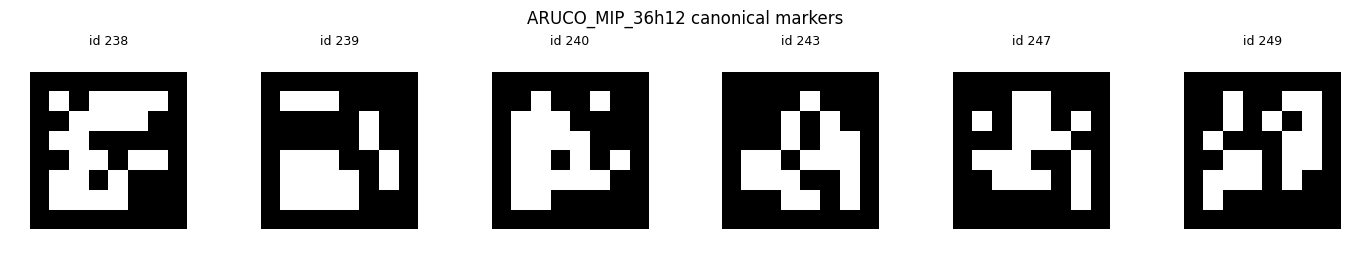

In [3]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 6, figsize=(14, 2.6))
for ax, i in zip(axes, [238, 239, 240, 243, 247, 249]):
    ax.imshow(render_marker(i, cell_px=20, quiet_cells=1), cmap="gray", interpolation="nearest")
    ax.set_title(f"id {i}", fontsize=9); ax.axis("off")
plt.suptitle("ARUCO_MIP_36h12 canonical markers")
plt.tight_layout(); plt.show()


## 4. Load Shadow-ArUco
Re-derives `pairs` from `ROOT` with assertions, so this cell is safe to run in a fresh runtime.
If an assertion fires, **fix the path — do not accept an auto-generated substitute dataset.**

In [9]:
import os, hashlib, subprocess
from google.colab import drive
drive.mount('/content/drive')

CACHE = '/content/drive/MyDrive/shadow_aruco'
TAR   = f'{CACHE}/video_1.tar.gz'
MD5   = '1c8bd58fb067a453487dfff783416674'
URL   = 'https://zenodo.org/records/10791293/files/video_1.tar.gz'
os.makedirs(CACHE, exist_ok=True)

def md5sum(p, chunk=1 << 20):
    h = hashlib.md5()
    with open(p, 'rb') as f:
        for b in iter(lambda: f.read(chunk), b''):
            h.update(b)
    return h.hexdigest()

if not os.path.exists(TAR) or md5sum(TAR) != MD5:
    print('downloading (~7 min)...')
    subprocess.run(['curl', '-L', '-o', TAR, URL], check=True)
    got = md5sum(TAR)
    assert got == MD5, f'CHECKSUM MISMATCH {got} — delete {TAR} and retry'
print('archive verified')

if not os.path.isdir('/content/video_1'):
    os.chdir('/content')
    subprocess.run(['tar', '-xzf', TAR], check=True)

print('frames:', len(os.listdir('/content/video_1')) - 1)

Mounted at /content/drive
archive verified
frames: 1433


In [10]:
import os, glob, json
import numpy as np

ROOT = "/content/video_1"
assert os.path.isdir(ROOT), f"{ROOT} not found — extract video_1.tar.gz first"

pairs = []
for f in sorted(glob.glob(os.path.join(ROOT, "*.png"))):
    idx = os.path.splitext(os.path.basename(f))[0]
    j = os.path.join(ROOT, "corrected_annotations", f"{idx}.json")
    if os.path.exists(j):
        pairs.append((f, j))

def get_corners(marker):
    c = marker["corners"]
    if isinstance(c[0], dict):
        return np.array([[p["x"], p["y"]] for p in c], dtype=np.float32)
    return np.asarray(c, dtype=np.float32).reshape(4, 2)

ids_seen = set()
for _, j in pairs:
    with open(j) as fp:
        ids_seen.update(int(m["id"]) for m in json.load(fp)["markers"])

print("pairs     :", len(pairs))
print("unique IDs:", sorted(ids_seen))
assert len(pairs) > 1000, f"REAL DATA NOT LOADED: {len(pairs)} pairs (expected 1433)"
assert ids_seen == set(range(238, 250)), f"unexpected IDs: {sorted(ids_seen)}"
print("\nreal Shadow-ArUco video_1 confirmed")


pairs     : 1433
unique IDs: [238, 239, 240, 241, 242, 243, 244, 245, 246, 247, 248, 249]

real Shadow-ArUco video_1 confirmed


## 5. Classical baseline

Every 6th frame — six fixed cameras mean adjacent frames are near-duplicates, so the effective
sample size was never 8652.

`DICT_6X6_250` is included as a control. It should stay at exactly 0.0000 while MIP36h12 goes
non-zero. That contrast is the result: **classical ArUco does work on this dataset, it just
performs poorly**, which is the reason the dataset exists and is a reportable baseline.

In [11]:
clahe = cv2.createCLAHE(clipLimit=3.0, tileGridSize=(8, 8))

params = cv2.aruco.DetectorParameters()
params.adaptiveThreshWinSizeMin, params.adaptiveThreshWinSizeMax = 3, 53
params.adaptiveThreshWinSizeStep = 4
params.minMarkerPerimeterRate = 0.01
params.polygonalApproxAccuracyRate = 0.06

DICTS = {
    "ARUCO_MIP_36h12": get_dictionary(),
    "DICT_6X6_250 (control)": cv2.aruco.getPredefinedDictionary(cv2.aruco.DICT_6X6_250),
}

print(f"{'dictionary':<24}{'prep':<8}{'recall':>10}{'hits':>10}{'falseID':>10}")
print("-" * 62)
results = {}
for dname, d in DICTS.items():
    det = cv2.aruco.ArucoDetector(d, params)
    for label, prep in [("raw", lambda g: g), ("clahe", lambda g: clahe.apply(g))]:
        tp = fp_ = tot = 0
        for f, j in pairs[::6]:
            _, ids, _ = det.detectMarkers(prep(cv2.imread(f, cv2.IMREAD_GRAYSCALE)))
            with open(j) as fpp:
                gt = [int(m["id"]) for m in json.load(fpp)["markers"]]
            tot += len(gt)
            if ids is not None:
                for i in ids.flatten().tolist():
                    tp += int(i) in gt
                    fp_ += int(i) not in gt
        results[(dname, label)] = tp / max(tot, 1)
        print(f"{dname:<24}{label:<8}{tp/max(tot,1):>10.4f}{tp:>10}{fp_:>10}")

mip = max(results[("ARUCO_MIP_36h12", p)] for p in ("raw", "clahe"))
ctl = max(results[("DICT_6X6_250 (control)", p)] for p in ("raw", "clahe"))
print()
if mip > 0 and ctl == 0:
    print(f"CONFIRMED: MIP36h12 recall {mip:.4f}, control exactly 0. Dictionary identified.")
elif mip == 0:
    print("MIP36h12 still 0 — markers may be too small/dark for the detector at these settings.")
    print("Sanity check: run detectMarkers on render_marker(238) from Cell 3.")


dictionary              prep        recall      hits   falseID
--------------------------------------------------------------
ARUCO_MIP_36h12         raw         0.3909      1121         1
ARUCO_MIP_36h12         clahe       0.6154      1765         0
DICT_6X6_250 (control)  raw         0.0000         0         0
DICT_6X6_250 (control)  clahe       0.0000         0         0

CONFIRMED: MIP36h12 recall 0.6154, control exactly 0. Dictionary identified.


## 6. Decodability ceiling from ground-truth corners

Independent of the detector: rectify from GT corners, read bits, decode against MIP36h12.
This separates **localisation** failure from **recognition** failure — the same distinction that
became the thesis of Project 1.

The Hamming histogram is what motivates erasure decoding. Markers landing at distance 6-11 are
undecodable by standard error correction (limit 5) but recoverable if the unreadable cells are
marked as erasures instead of guessed (limit 11).

markers evaluated from GT corners: 2868

  exact (H=0)                    :  62.4%
  correctable, H<=5 (standard)   :  82.8%
  erasure range, H<=11          :  95.6%
  mean Hamming                   :   2.17   (chance ~14.9)


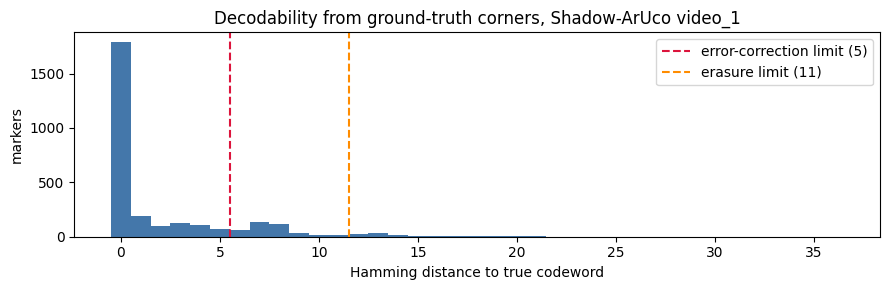

In [12]:
def rectify(gray, corners, out_px):
    dst = np.array([[0,0],[out_px-1,0],[out_px-1,out_px-1],[0,out_px-1]], dtype=np.float32)
    H = cv2.getPerspectiveTransform(corners.astype(np.float32), dst)
    return cv2.warpPerspective(gray, H, (out_px, out_px), flags=cv2.INTER_LINEAR)

def normalise(crop):
    f = crop.astype(np.float32)
    bg = cv2.GaussianBlur(f, (0, 0), sigmaX=max(crop.shape[0] / 4.0, 1.0))
    return cv2.normalize(f / (bg + 1.0), None, 0, 255, cv2.NORM_MINMAX).astype(np.uint8)

def read_bits(crop):
    s = crop.shape[0] / 8.0
    img = normalise(crop)
    M = np.zeros((8, 8), np.float32)
    for r in range(8):
        for c in range(8):
            y0, x0 = int(r*s + s*0.25), int(c*s + s*0.25)
            y1, x1 = int(r*s + s*0.75), int(c*s + s*0.75)
            M[r, c] = img[y0:y1, x0:x1].mean()
    thr, _ = cv2.threshold(M.reshape(-1).astype(np.uint8), 0, 255,
                           cv2.THRESH_BINARY + cv2.THRESH_OTSU)
    return (M[1:-1, 1:-1] > thr).astype(np.uint8)

dists = []
for f, j in pairs[::6]:
    gy = cv2.imread(f, cv2.IMREAD_GRAYSCALE)
    with open(j) as fp:
        g = json.load(fp)
    for m in g["markers"]:
        cn = get_corners(m)
        side = np.mean([np.linalg.norm(cn[i] - cn[(i+1) % 4]) for i in range(4)])
        if side < 24:
            continue
        obs = read_bits(rectify(gy, cn, 96))
        ref = id_to_bits(int(m["id"]))
        dists.append(min(int(np.sum(np.rot90(obs, k) != ref)) for k in range(4)))

d = np.array(dists)
print(f"markers evaluated from GT corners: {len(d)}\n")
print(f"  exact (H=0)                    : {(d==0).mean():6.1%}")
print(f"  correctable, H<={MAX_ERROR_CORRECTION} (standard)   : {(d<=MAX_ERROR_CORRECTION).mean():6.1%}")
print(f"  erasure range, H<={MAX_ERASURE_CORRECTION}          : {(d<=MAX_ERASURE_CORRECTION).mean():6.1%}")
print(f"  mean Hamming                   : {d.mean():6.2f}   (chance ~14.9)")

plt.figure(figsize=(9, 3))
plt.hist(d, bins=np.arange(38) - 0.5, color="#4477aa")
plt.axvline(MAX_ERROR_CORRECTION + 0.5, color="crimson", ls="--",
            label=f"error-correction limit ({MAX_ERROR_CORRECTION})")
plt.axvline(MAX_ERASURE_CORRECTION + 0.5, color="darkorange", ls="--",
            label=f"erasure limit ({MAX_ERASURE_CORRECTION})")
plt.xlabel("Hamming distance to true codeword"); plt.ylabel("markers")
plt.title("Decodability from ground-truth corners, Shadow-ArUco video_1")
plt.legend(); plt.tight_layout(); plt.show()
